# Interference-Aware Write Control for Bounded-Memory Recurrent Models
## Prototype notebook, midpoint draft (EN.705.742, RP2)

**Ryan Ellis, 2026-10-25.** Companion to `paper/Ellis-RP2.pdf`.

This notebook runs the prototype end to end on sample data so the pieces described in the
paper can be inspected: the task generator (Section III-A), the model with its slot memory and
writers (III-B to III-D), a short training run with the metrics and paired-bootstrap statistics
of the protocol (IV-A), and the single-seed pilot (IV-B). The short training run here uses a
small task (8 queried pairs, 2 updates, 2 distractors, 16 slots, 800 steps) chosen so recall
leaves chance within a few minutes on one GPU. It is a pipeline check, not a result; the pilot
numbers at the end come from the 16-minute runs reported in the paper.

**Requirements.** Python 3.11+, PyTorch with CUDA, and `flash-linear-attention` (the GLA
backbone kernel), installed from `requirements.txt`. The memory loop and the backbone kernels
need a GPU; the notebook was run on an RTX 5090. Run from the project root so `src/` is
importable.


In [1]:
import sys, time, json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src" / "bmem").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt

from bmem.data import MQARConfig, MQARBatch, generate_mqar, make_splits, IGNORE
from bmem.model import ModelConfig, RecallModel
from bmem.controller import WRITERS
from bmem.train import TrainConfig, train, evaluate
from bmem.metrics import recall_per_example, bootstrap_ci, paired_bootstrap_ci

assert torch.cuda.is_available(), "the prototype needs a CUDA GPU (memory loop + GLA kernels)"
device = torch.device("cuda")
torch.manual_seed(0); np.random.seed(0)
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 NVIDIA GeForce RTX 5090


## 1. Sample data: MQAR with updates and distractors

Each sequence has a *context block* of key-value pairs (queried pairs plus distractor pairs
whose keys are never asked about), an *update block* where some queried keys reappear with a
new value, and a *query region* where each queried key appears once more and the label is its
latest value. Token 0 is filler, keys are `1 .. vocab/2 - 1`, values are `vocab/2 .. vocab - 1`.
Labels are `-100` everywhere except at answer positions, so the loss and the recall metric see
only the answers.

The configuration below is deliberately tiny so one sequence fits on screen.

In [2]:
tiny = MQARConfig(vocab_size=64, seq_len=32, num_kv_pairs=4, num_updates=1, num_distractors=1, random_non_queries=False)
sample = generate_mqar(tiny, num_examples=3, seed=0)
x, y = sample.inputs[0].tolist(), sample.labels[0].tolist()
half = tiny.vocab_size // 2

def kind(tok):
    if tok == 0: return "filler"
    return "KEY" if tok < half else "val"

print(f"{'pos':>3} {'token':>5} {'kind':>6} {'label':>5}")
for t, (tok, lab) in enumerate(zip(x, y)):
    print(f"{t:>3} {tok:>5} {kind(tok):>6} {'' if lab == IGNORE else lab:>5}")
print("\ncontext tokens:", tiny.context_tokens(), " answer positions:", sum(l != IGNORE for l in y))

pos token   kind label
  0     3    KEY      
  1    58    val      
  2     4    KEY      
  3    50    val      
  4    14    KEY      
  5    56    val      
  6    21    KEY      
  7    47    val      
  8    12    KEY      
  9    52    val      
 10    14    KEY      
 11    63    val      
 12    21    KEY    47
 13     0 filler      
 14    14    KEY    63
 15     0 filler      
 16     0 filler      
 17     0 filler      
 18     0 filler      
 19     0 filler      
 20     4    KEY    50
 21     0 filler      
 22     0 filler      
 23     0 filler      
 24     0 filler      
 25     0 filler      
 26    12    KEY    52
 27     0 filler      
 28     0 filler      
 29     0 filler      
 30     0 filler      
 31     0 filler      

context tokens: 12  answer positions: 4


Reading the dump: the first `context_tokens` positions alternate KEY, val; one of those keys
is a distractor that is never queried. The update block repeats one queried key with a new
value. Each labelled position is a query: the input is a KEY token and the label is the value
most recently paired with it. Check for yourself that the label for the updated key is the
*new* value, not the one from the context block.

The splits used for training come from distinct seeds, with exact-duplicate sequences removed
from validation and test; the count of duplicates dropped is recorded so the disjointness claim
in the paper is verifiable.

In [3]:
small = MQARConfig(vocab_size=512, seq_len=64, num_kv_pairs=8, num_updates=2, num_distractors=2, power_a=0.01, min_delay=0)
splits = make_splits(small, n_train=20000, n_val=512, n_test=1000, seed=0)
for name, s in splits.items():
    print(f"{name:>5}: {len(s):>5} sequences of length {s.inputs.shape[1]}, duplicates dropped: {s.meta.get('duplicates_dropped', 0)}")
print("associations per sequence:", small.num_kv_pairs + small.num_updates + small.num_distractors)

train: 20000 sequences of length 64, duplicates dropped: 0
  val:   512 sequences of length 64, duplicates dropped: 0
 test:  1000 sequences of length 64, duplicates dropped: 0
associations per sequence: 12


## 2. The model: GLA backbone, slot memory, and the five writers

Every writer shares the backbone, the q/k/v projections, the slot memory, and the answer head
(Fig. 1 of the paper). Only the rule that produces the per-slot write gates differs. The
parameter and state-byte accounting below is what the paper's Table II reports, here at the
small size (16 slots, memory dim 64, 2 layers of width 128).

In [4]:
small_model = dict(vocab_size=small.vocab_size, d_model=128, n_layers=2, n_heads=2, slots=16, mem_dim=64)
rows = []
for name in WRITERS:
    m = RecallModel(ModelConfig(**small_model, writer=name))
    p, sb = m.n_params(), m.state_bytes()
    rows.append((name, p["total"], p["writer"], sb["backbone"], sb["memory"], sb["writer"], sb["total"]))
print(f"{'writer':<16}{'params':>9}{'writer params':>15}{'state: backbone':>17}{'memory':>8}{'writer':>8}{'total':>8}  (bytes / sequence)")
for r in rows:
    print(f"{r[0]:<16}{r[1]:>9,}{r[2]:>15,}{r[3]:>17,}{r[4]:>8,}{r[5]:>8,}{r[6]:>8,}")

writer             params  writer params  state: backbone  memory  writer   total  (bytes / sequence)
controller        586,515          1,859           32,768   8,384       0  41,152
no_interference   586,515          1,859           32,768   8,384       0  41,152
recency           582,592              0           32,768   8,384       0  41,152
residual          582,594              2           32,768   8,384       4  41,156
position          582,592              0           32,768   8,384       0  41,152


The controller and its no-interference ablation have the same parameter count: the ablation
zeroes two of the six per-slot features (Eq. 3) and changes nothing else, which is what makes it
a clean test of H2. The three rule-based writers add no parameters except the residual writer's
learned threshold and slope, and none of the writers adds per-sequence state beyond the memory's
own age, usage, and occupancy scalars.

### Where does each writer put things at initialization?

One forward pass with `return_gates=True` records the gate vector at every position. For the
controller the forward pass writes exactly one slot (straight-through hard gate, Eq. 4) scaled
by the write probability. At initialization the recency prior makes it behave like the recency
writer; training moves it away from that.

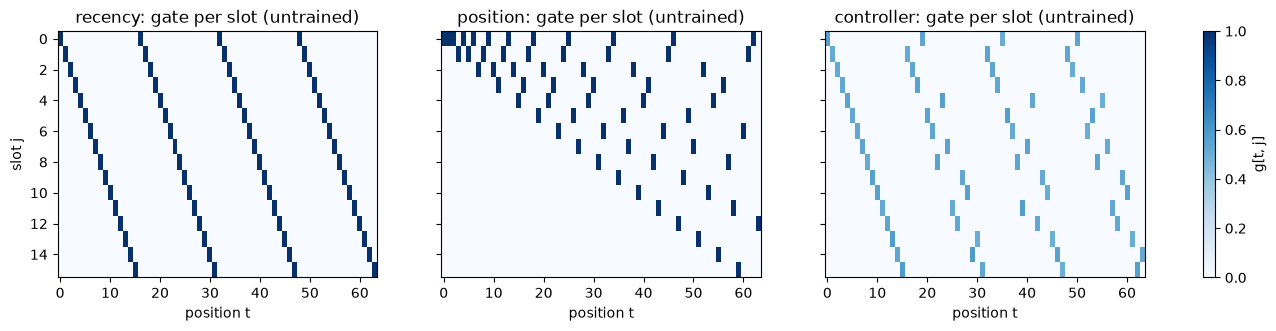

In [5]:
x = splits["train"].inputs[:4].to(device)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, name in zip(axes, ["recency", "position", "controller"]):
    m = RecallModel(ModelConfig(**small_model, writer=name)).to(device).eval()
    with torch.no_grad():
        _, info = m(x, return_gates=True)
    g = info["gates"][0].float().cpu().numpy()  # (T, slots) for sequence 0
    im = ax.imshow(g.T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{name}: gate per slot (untrained)"); ax.set_xlabel("position t")
axes[0].set_ylabel("slot j")
fig.colorbar(im, ax=axes, fraction=0.015, label="g[t, j]")
plt.show()

Recency fills the empty slots in order and then cycles through the oldest; position activation
unlocks slots on a schedule, so early tokens can only use the first slot(s); the untrained
controller follows the recency prior but with gate mass below one because its write probability
$\sigma(w_t)$ starts near 0.5 and nothing has yet taught it which tokens are worth storing.

## 3. Prototype training run (small task)

This trains the controller and the recency writer for 800 steps on the 8-pair task above. It
is the setting of the repository's GPU learnability regression test (`pytest -m slow`), the
smallest task on which recall reliably leaves chance in about a minute, and it is far too small
to say anything about the hypotheses. Its purpose is to show the training loop, the validation
curve, the evaluation, and the statistics running on real code. The `train` function is the
same one `experiments/run.py` uses for the pilot and will use for the full sweep.

In [6]:
tcfg = TrainConfig(steps=800, batch_size=64, lr=1e-3, warmup=50, eval_every=100, eval_batches=4, seed=0)
results = {}
for name in ["controller", "recency"]:
    torch.manual_seed(0)
    model = RecallModel(ModelConfig(**small_model, writer=name))
    print(f"=== {name}: {model.n_params()['total']:,} params")
    stats = train(model, splits["train"], splits["val"], tcfg, device, log=lambda s: print("   ", s) if "eval" in s else None)
    ev = evaluate(model, splits["test"], device, bf16=tcfg.bf16)
    results[name] = {"model": model, "history": stats["history"], "test": ev,
                     "train_s": stats["train_seconds"], "tok_s": stats["train_tokens_per_s"], "peak_mb": stats["peak_mem_mb"]}
    print(f"    test recall {ev['recall']:.3f}  95% CI {np.round(ev['recall_ci95'], 3).tolist()}   "
          f"train {stats['train_seconds']:.0f}s, {stats['train_tokens_per_s']/1e3:.0f}k tok/s, peak {stats['peak_mem_mb']:.0f} MB")

=== controller: 586,515 params


      eval step 100: val recall 0.0039 ci [0.002197265625, 0.005859375]


      eval step 200: val recall 0.0081 ci [0.005615234375, 0.0107421875]


      eval step 300: val recall 0.2642 ci [0.25146484375, 0.2771057188510895]


      eval step 400: val recall 0.4673 ci [0.452880859375, 0.483154296875]


...

      eval step 400: val recall 0.2568 ci [0.244873046875, 0.268798828125]


      eval step 500: val recall 0.2991 ci [0.28662109375, 0.31103515625]


      eval step 600: val recall 0.3091 ci [0.296142578125, 0.3212890625]


      eval step 700: val recall 0.3101 ci [0.297607421875, 0.321533203125]


      eval step 800: val recall 0.3132 ci [0.3007751405239105, 0.32470703125]
    test recall 0.319  95% CI [0.311, 0.327]   train 20s, 160k tok/s, peak 143 MB


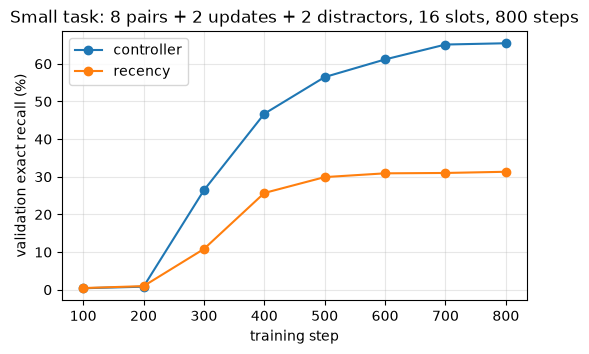

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, r in results.items():
    h = r["history"]
    ax.plot([e["step"] for e in h], [100 * e["val_recall"] for e in h], marker="o", label=name)
ax.set_xlabel("training step"); ax.set_ylabel("validation exact recall (%)")
ax.set_title("Small task: 8 pairs + 2 updates + 2 distractors, 16 slots, 800 steps")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 4. Metrics and statistics used for the hypothesis tests

The primary metric is **exact recall**: the fraction of answer positions predicted exactly,
computed per sequence (`recall_per_example`) so that confidence intervals can be formed over
test sequences. Each cell of the final sweep reports a 95% bootstrap interval, and H1 is tested
with a **paired** bootstrap on the per-sequence difference between the controller and the best
baseline, which is valid because every writer is evaluated on the same test sequences. The cell
below runs exactly that machinery on the two models just trained. One seed on a toy task is
not evidence for or against H1; the point is that the statistics pipeline runs. For the full sweep this cell becomes
`experiments/aggregate.py`, which does the same over three seeds per cell.

In [8]:
a = results["controller"]["test"]["per_example"]
b = results["recency"]["test"]["per_example"]
print(f"n test sequences: {len(a)}")
for name, arr in [("controller", a), ("recency", b)]:
    lo, hi = bootstrap_ci(arr)
    print(f"{name:<11} recall {100*arr.mean():5.1f}%   95% bootstrap CI [{100*lo:5.1f}, {100*hi:5.1f}]")
lo, hi = paired_bootstrap_ci(a, b)
print(f"\npaired difference (controller - recency): {100*(a-b).mean():+5.1f} pp   95% paired CI [{100*lo:+5.1f}, {100*hi:+5.1f}]")
print("H1 asks for >= +5 pp against the *strongest* validation-selected baseline at N=64, S=32 over 3 seeds; this toy comparison is a pipeline check only.")

n test sequences: 1000
controller  recall  66.5%   95% bootstrap CI [ 65.6,  67.5]
recency     recall  31.9%   95% bootstrap CI [ 31.1,  32.7]

paired difference (controller - recency): +34.6 pp   95% paired CI [+33.4, +35.8]
H1 asks for >= +5 pp against the *strongest* validation-selected baseline at N=64, S=32 over 3 seeds; this toy comparison is a pipeline check only.


## 5. Pilot results (seed 0, 24 associations, 16 slots)

The paper's Table II comes from `experiments/run.py` with `experiments/configs/pilot16.yaml`, one
seed per writer, about 16 minutes each on an RTX 5090. The `runs/` directory is not committed,
so this cell loads the saved `results.json` files if they are present on this machine and
otherwise prints the numbers as reported in the paper. The per-sequence recall arrays saved by
`run.py` are what the paired bootstrap in the paper used.

In [9]:
PAPER_TABLE = {   # from paper/Ellis-RP2.pdf, Table II (recall %, 95% CI), in case runs/ is absent
    "controller":      {"L128": (51.9, 51.7, 52.2), "L256": (52.1, 51.9, 52.3), "L512": (52.1, 51.9, 52.3)},
    "no_interference": {"L128": (50.7, 50.5, 50.9), "L256": (50.8, 50.6, 51.0), "L512": (50.9, 50.6, 51.1)},
    "recency":         {"L128": (11.0, 10.9, 11.1), "L256": ( 9.6,  9.5,  9.7), "L512": ( 8.7,  8.6,  8.8)},
}
pilot_dir = ROOT / "runs" / "pilot16"
print(f"{'writer':<17}{'L=128':>22}{'L=256':>22}{'L=512':>22}")
per_ex = {}
for w in PAPER_TABLE:
    f = pilot_dir / f"{w}_s0" / "results.json"
    if f.exists():
        ev = json.loads(f.read_text())["eval"]
        cells = [(100*ev[L]["recall"], 100*ev[L]["recall_ci95"][0], 100*ev[L]["recall_ci95"][1]) for L in ("L128", "L256", "L512")]
        per_ex[w] = np.load(pilot_dir / f"{w}_s0" / "per_example_L128.npy")
        src = "runs/"
    else:
        cells, src = list(PAPER_TABLE[w].values()), "paper"
    print(f"{w:<17}" + "".join(f"{m:6.1f} [{lo:5.1f}, {hi:5.1f}]   " for m, lo, hi in cells) + f" ({src})")
if {"controller", "no_interference", "recency"} <= per_ex.keys():
    for other in ["no_interference", "recency"]:
        d = per_ex["controller"] - per_ex[other]
        lo, hi = paired_bootstrap_ci(per_ex["controller"], per_ex[other])
        print(f"paired, L=128: controller - {other:<16} {100*d.mean():+5.1f} pp  95% CI [{100*lo:+5.1f}, {100*hi:+5.1f}]  (n={len(d)})")

writer                            L=128                 L=256                 L=512
controller         51.9 [ 51.7,  52.2]     52.1 [ 51.9,  52.3]     52.1 [ 51.9,  52.3]    (runs/)
no_interference    50.7 [ 50.5,  50.9]     50.8 [ 50.6,  51.0]     50.9 [ 50.6,  51.1]    (runs/)
recency            11.0 [ 10.9,  11.1]      9.6 [  9.5,   9.7]      8.7 [  8.6,   8.8]    (runs/)


paired, L=128: controller - no_interference   +1.3 pp  95% CI [ +1.0,  +1.5]  (n=10000)
paired, L=128: controller - recency          +40.9 pp  95% CI [+40.7, +41.2]  (n=10000)


## 6. Placeholders for the final paper

The following are implemented in the repository but not yet run; they become Sections IV-B and
IV-C of the final paper.

| Item | Status | Where |
|---|---|---|
| Full factorial sweep: $S \in \{32,64,128\}$, $N \in \{64,128\}$, 5 writers, 3 seeds | protocol fixed, not run | `experiments/configs/pilot16.yaml` → sweep configs |
| Residual-cache and position-activation baselines trained and tuned on validation | implemented, unit-tested, untrained | `src/bmem/controller.py` |
| Write-admission logging (which token kinds each writer admits) | planned | `RecallModel(..., return_gates=True)` + token kinds as in Section 1 |
| Curriculum from 16 pairs up to the 64-association target | planned | `experiments/run.py` |
| Vectorized or fused write loop (currently 98% of step time) | planned | `src/bmem/model.py` forward loop |
| Aggregation over seeds with bootstrap and paired-bootstrap intervals | implemented | `experiments/aggregate.py` |

Reproducing the pilot from the command line:

```bash
source ~/venvs/jhu-742/bin/activate
pytest                                     # fast unit tests
python experiments/run.py --config experiments/configs/pilot16.yaml --writer controller --seed 0 --out_dir runs/pilot16/controller_s0
python experiments/run.py --config experiments/configs/pilot16.yaml --writer no_interference --seed 0 --out_dir runs/pilot16/no_interference_s0
python experiments/run.py --config experiments/configs/pilot16.yaml --writer recency --seed 0 --out_dir runs/pilot16/recency_s0
python experiments/aggregate.py runs/pilot16 --pair controller no_interference
```
